# UMAP map of the biodiversity-loss literature

Supplementary Figures S7–S9. One point per article reporting negative biodiversity change (`s2_dir == "negative"`, 253,081 articles), positioned by the precomputed two-dimensional UMAP layout of its title-and-abstract embedding (`umap_coordinates.parquet`; see `umap_manifest.json`).
- Colour modes: ecosystem realm (S7), IPBES direct driver (S8) and taxonomic class (S9).
- Counting is by unique document. An article naming several labels is coloured by its most frequent label; the legend percentage is the share of all plotted records that name the label, so legend shares can sum to more than 100%.
- The class map shows the 11 most frequent classes; all other classes are pooled as "Other classes" (grey). It includes only articles with a class label, so its n is smaller than 253,081 (in the file name).
- Articles whose label is `Not Applicable` (or empty) are drawn in grey and left out of the legend.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / "data_helpers").is_dir() and (candidate / "checklists").is_dir():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the biodiversity repository root.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data_helpers import results_config, visualization
from data_helpers.analysis import embedding_map

## 1. Inputs

In [3]:
visualization.apply_style()
plt.rcParams["figure.constrained_layout.use"] = False

RESULTS_CONFIG = results_config.load_results_config()
MAP_CONFIG = RESULTS_CONFIG["embedding_map"]

OUTPUT_DIR = PROJECT_ROOT / MAP_CONFIG["output_directory"]
TABLE_DIR = OUTPUT_DIR / MAP_CONFIG["table_subdirectory"]
FIGURE_DIR = OUTPUT_DIR / MAP_CONFIG["figure_subdirectory"]
for directory in (TABLE_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DATASET_PATH = PROJECT_ROOT / MAP_CONFIG["dataset_source"]
UMAP_PATH = PROJECT_ROOT / MAP_CONFIG["umap_source"]

# Provenance: the complete set of inputs this result depends on.
print("Inputs")
for label, path in (("dataset", DATASET_PATH), ("UMAP coordinates", UMAP_PATH)):
    status = "found" if path.exists() else "MISSING"
    print(f"  {label:<17} {path.relative_to(PROJECT_ROOT)}  [{status}]")
missing = [path for path in (DATASET_PATH, UMAP_PATH) if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing inputs: {[str(p.relative_to(PROJECT_ROOT)) for p in missing]}")
print(f"\nOutput section: {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Inputs
  dataset           notebooks/data_processing/outputs/04_dataset/dataset.parquet  [found]
  UMAP coordinates  notebooks/data_processing/outputs/04_dataset/umap_coordinates.parquet  [found]

Output section: notebooks/results/outputs/06_embedding_map


In [4]:
dataset = pd.read_parquet(
    DATASET_PATH, columns=[
        "UT", "s2_dir", "driver", "realm", "taxa_class_labels"
    ]
)
coordinates = pd.read_parquet(UMAP_PATH, columns=["UT", "umap_x", "umap_y"])
frame = embedding_map.join_coordinates(dataset, coordinates)
n_corpus = len(frame)
frame = frame.loc[frame["s2_dir"] == MAP_CONFIG["direction"]].reset_index(drop=True)
print(
    f"{n_corpus:,} articles joined to UMAP coordinates on UT (no missing, no duplicates); "
    f"{len(frame):,} kept with s2_dir == {MAP_CONFIG['direction']!r}."
)

605,199 articles joined to UMAP coordinates on UT (no missing, no duplicates); 253,081 kept with s2_dir == 'negative'.


## 2. Colour modes

Colours are set in the `embedding_map` block of `results_config.json`. Legend order is descending document count.

In [5]:
_, _, driver_names = results_config.driver_l1_display(RESULTS_CONFIG)

# Drivers have fixed colours; realms and classes take the ranked palette in
# legend (descending document count) order.
TOP_N_TAXA = 11
MODES = {
    "realm": dict(column="realm", colors=None, names={}),
    "direct_drivers": dict(column="driver", colors=MAP_CONFIG["driver_colors"], names=driver_names),
    # Classes: keep the 11 most frequent, pool the rest; drawn only for articles with a class label.
    "class": dict(column="taxa_class_labels", colors=None, names={}, top_n=TOP_N_TAXA, other_label="Other classes", require_label=True),
}

labelled = {}
mode_frames = {}
for mode, spec in MODES.items():
    mode_frame = frame
    if spec.get("require_label"):
        mode_frame = frame.loc[frame[spec["column"]].map(len) > 0].reset_index(drop=True)
    mode_frames[mode] = mode_frame
    spec["n_tag"] = f"{len(mode_frame):_}"  # e.g. 253_081, appended to the figure filename
    labelled[mode] = embedding_map.assign_labels(
        mode_frame[spec["column"]],
        skip=spec.get("skip", ("Not Applicable",)),
        top_n=spec.get("top_n"),
        other_label=spec.get("other_label", "Other"),
    )
    summary = labelled[mode].summary
    if spec["colors"] is None:
        spec["colors"] = dict(zip(summary["label"], MAP_CONFIG["ranked_palette"]))
    skipped = int((labelled[mode].codes == 0).sum())
    print(f"\n{mode}: n = {len(mode_frame):,}; {skipped:,} with no plotted label (grey)")
    display(
        summary.style.format({"n_documents": "{:,}", "share_pct": "{:.1f}%"}).hide(axis="index")
    )


realm: n = 253,081; 12,240 with no plotted label (grey)


label,n_documents,share_pct
Terrestrial,"118,622",46.9%
Freshwater,"67,003",26.5%
Marine,"37,503",14.8%
Freshwater-Marine,"8,764",3.5%
Marine-Terrestrial,"3,311",1.3%
Freshwater-Terrestrial,"2,635",1.0%
Subterranean-Freshwater,"1,155",0.5%
Subterranean,"1,096",0.4%
All realms,635,0.3%
Marine-Freshwater-Terrestrial,416,0.2%



direct_drivers: n = 253,081; 0 with no plotted label (grey)


label,n_documents,share_pct
Pollution,"113,286",44.8%
Land/sea use change,"77,410",30.6%
Climate Change,"53,120",21.0%
Direct Exploitation and Resource Extraction,"40,091",15.8%
Invasive alien species,"26,397",10.4%



class: n = 163,227; 0 with no plotted label (grey)


label,n_documents,share_pct
Magnoliopsida,"33,750",20.7%
Teleostei,"27,709",17.0%
Mammalia,"22,109",13.5%
Liliopsida,"19,863",12.2%
Insecta,"13,545",8.3%
Aves,"10,141",6.2%
Pinopsida,"6,005",3.7%
Malacostraca,"5,929",3.6%
Gammaproteobacteria,"5,609",3.4%
Bivalvia,"5,584",3.4%


## 3. Figures

Saved: notebooks/results/outputs/06_embedding_map/figures/umap_realm_253_081.pdf


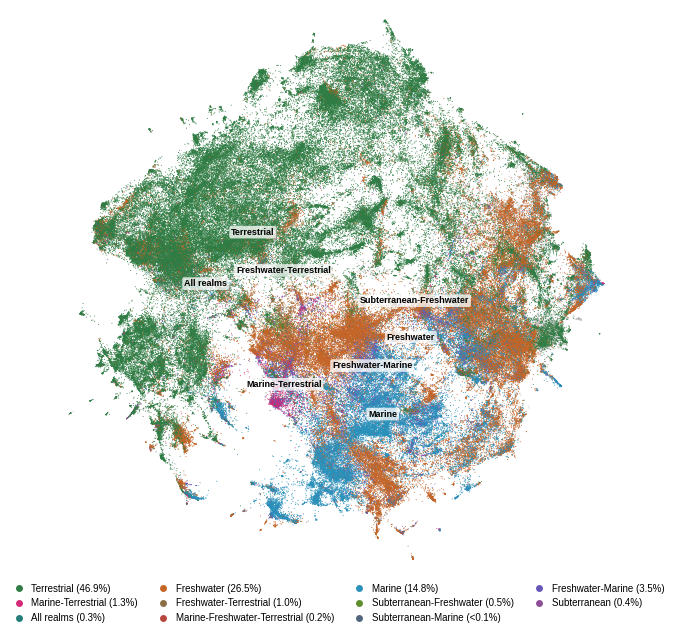

Saved: notebooks/results/outputs/06_embedding_map/figures/umap_direct_drivers_253_081.pdf


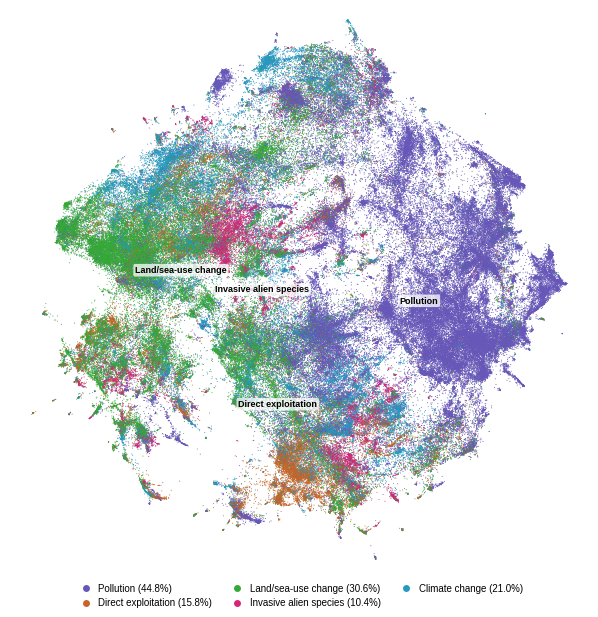

Saved: notebooks/results/outputs/06_embedding_map/figures/umap_class_163_227.pdf


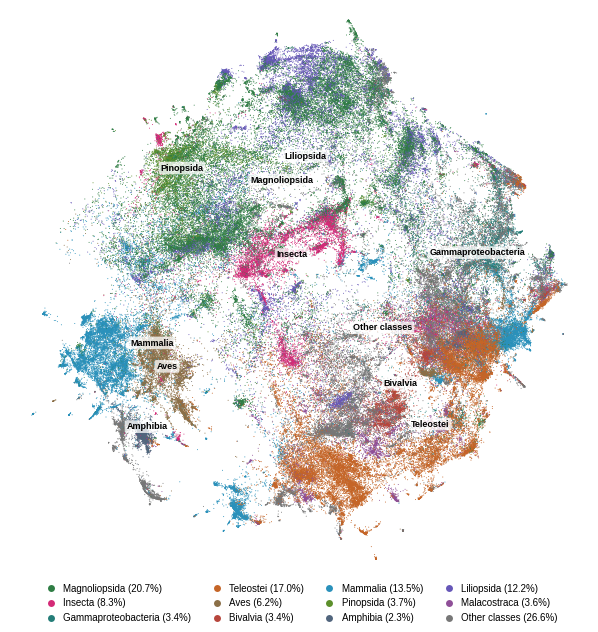

In [6]:
for mode, spec in MODES.items():
    mode_frame = mode_frames[mode]
    fig = embedding_map.plot_embedding_map(
        mode_frame["umap_x"].to_numpy(),
        mode_frame["umap_y"].to_numpy(),
        labelled[mode],
        colors=spec["colors"],
        display_names=spec["names"],
        point_size=MAP_CONFIG["point_size"],
        alpha=MAP_CONFIG["alpha"],
    )
    visualization.save_figure(fig, FIGURE_DIR / f"umap_{mode}_{spec['n_tag']}", formats=["pdf"], dpi=300)
    plt.show()

## 4. Export

In [7]:
for mode, spec in MODES.items():
    summary = labelled[mode].summary
    assert summary["share_pct"].between(0, 100).all()
    summary.to_csv(TABLE_DIR / f"umap_{mode}_distribution.csv", index=False)

manifest = {
    "result": "06_embedding_map",
    "method_details": {
        "n_articles": int(len(frame)),
        "n_corpus": int(n_corpus),
        "filter": f"s2_dir == {MAP_CONFIG['direction']!r} (biodiversity change direction)",
        "layout": "precomputed UMAP of nomic-embed-text (768-d) title-and-abstract embeddings; see umap_manifest.json",
        "taxa_top_n": TOP_N_TAXA,
        "colour_rule": "most frequent label (by unique-document count) wins for multi-label articles",
        "legend_share": "share of the records drawn in that map (its n) naming the label; may sum to more than 100%",
        "taxa_scope": "the class map draws only articles with a class label",
        "skipped_labels": ["Not Applicable", "empty list"],
        "modes": {
            mode: {
                "column": spec["column"],
                "n_articles": int(len(mode_frames[mode])),
                "n_unplotted": int((labelled[mode].codes == 0).sum()),
            }
            for mode, spec in MODES.items()
        },
    },
    "artifacts": {
        **{f"figures/umap_{m}_{MODES[m]['n_tag']}.pdf": f"UMAP scatter coloured by {m}." for m in MODES},
        **{f"csv/umap_{m}_distribution.csv": f"Label distribution for {m}." for m in MODES},
    },
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print((OUTPUT_DIR / "manifest.json").relative_to(PROJECT_ROOT))

notebooks/results/outputs/06_embedding_map/manifest.json
